<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<div style="text-align: center; margin-bottom: 10px;">
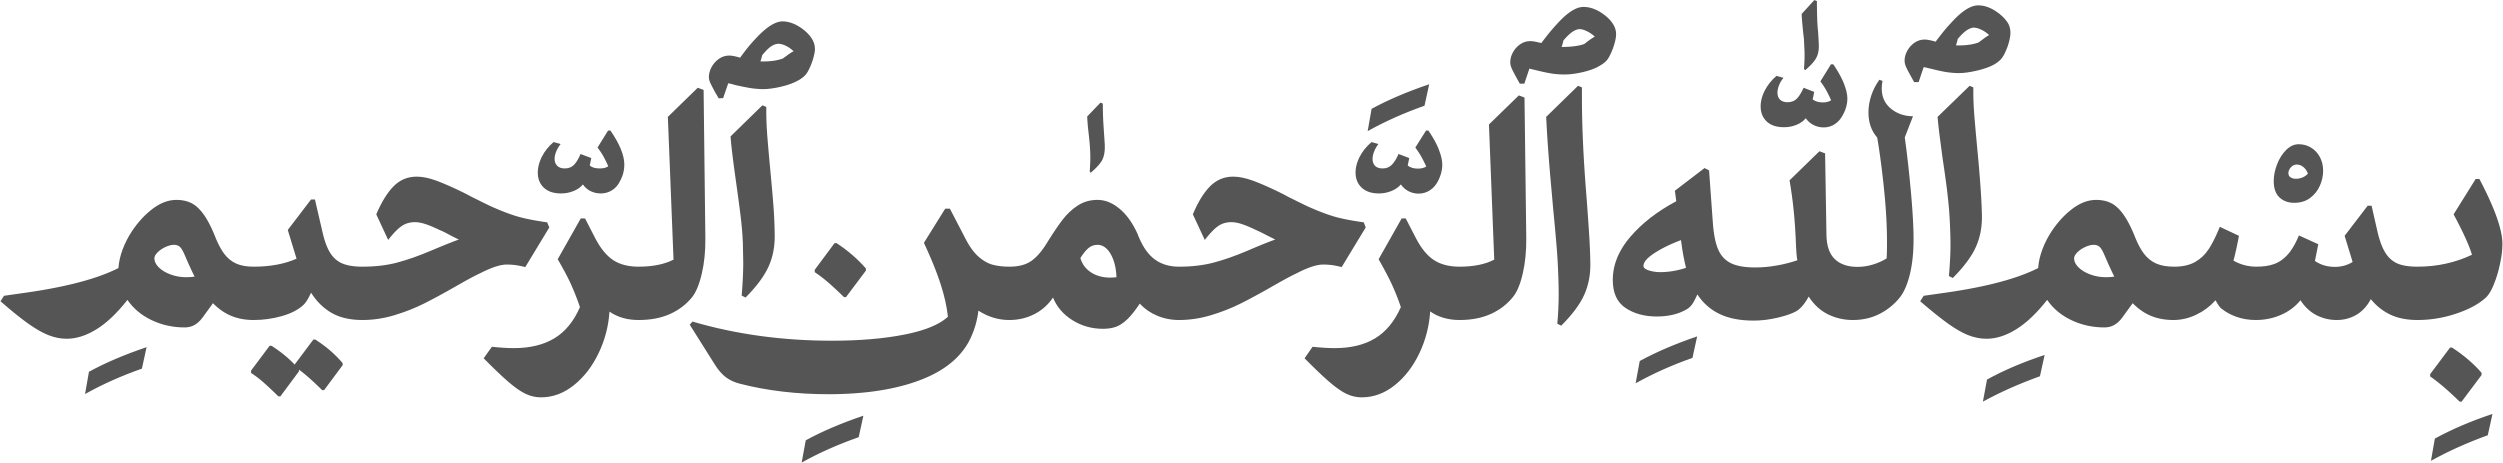
<div style="margin-top: 18px; display: flex; justify-content: center; align-items: center; gap: 30px;">
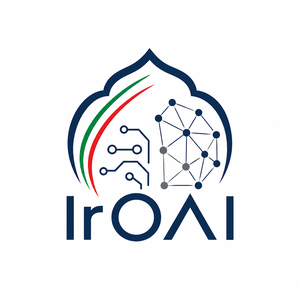
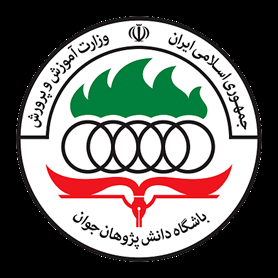
</div>
</div>
<h1 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">دوره تابستانه المپیاد هوش مصنوعی ایران — دوره دوم (۱۴۰۵)</h1>
<h2 style="text-align: right; color: #3498db;">مدل‌های زایشی: خودرمزگذار متغیر (VAE) و شبکه زایشی متخاصم (GAN) روی MNIST</h2>
<p style="text-align: right;"><b>موضوع:</b> یادگیری ژرف و مدل‌های زایشی — مبانی تئوری و پیاده‌سازی مقایسه‌ای VAE و GAN</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">این یک تمرین آموزشی هدایت‌شده (Guided Exercise) است؛ هیچ نمره‌ای از سامانه داوری دریافت نمی‌کند. هدف، یادگیری شهودی و بررسی نتایج کارهای پیاده‌سازی‌شده است.</p>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">اهداف یادگیری این دفترچه تمرین</h2>
<p style="text-align: right;">مدل‌سازی زایشی (Generative Modeling) یکی از هیجان‌انگیزترین شاخه‌های یادگیری ماشین است که هدف آن یادگیری توزیع حقیقی داده‌ها $p(x)$ و توانایی نمونه‌برداری از آن برای تولید نمونه‌های نو و باورپذیر است. در این دفترچه، دو خانواده بنیادین از این مدل‌ها یعنی <b>خودرمزگذارهای متغیر (VAE)</b> و <b>شبکه‌های زایشی متخاصم (GAN)</b> را روی دادگان استاندارد MNIST بررسی، پیاده‌سازی و مقایسه می‌کنیم.</p>

<p style="text-align: right;"><b>سرفصل‌های آموزشی که در این نوت‌بوک فرا خواهید گرفت:</b></p>
<ul style="text-align: right;">
<li style="text-align: right;">مفهوم مدل‌سازی زایشی و تفاوت بنیادین آن با مدل‌های تفکیک‌کننده (Discriminative) و خودرمزگذارهای کلاسیک (Deterministic Autoencoders).</li>
<li style="text-align: right;"><b>بخش اول — VAE:</b> شهود تئوری، فرمول‌بندی حقه بازپارامتری‌سازی (Reparameterization Trick) جهت امکان‌پذیری پس‌انتشار، بیشینه‌سازی حد پایین شواهد متغیر (ELBO) و واگرایی KL.</li>
<li style="text-align: right;">آموزش VAE، بازسازی ارقام، نمونه‌برداری از توزیع پیشین $p(z) = \mathcal{N}(0, I)$، پیمایش و درهم‌آمیزی (Interpolation) در فضای نهفته دوبعدی.</li>
<li style="text-align: right;"><b>بخش دوم — GAN:</b> بازی دو نفره مینی‌ماکس میان مولد (Generator) و متمایزگر (Discriminator)، معماری استاندارد FC-GAN با لایه‌های Dropout و LeakyReLU، و آموزش پایدار طی ۱۰۰ دوره.</li>
<li style="text-align: right;">بررسی دینامیک آموزش، توابع D_train و G_train، عدم وقوع واگرایی متمایزگر و روند تکامل تدریجی وضوح ارقام در طول دوره‌ها.</li>
<li style="text-align: right;"><b>بخش سوم — تحلیل مقایسه‌ای:</b> مقایسه مستقیم وضوح ارقام، تبیین ریاضی و هندسی پدیده «میانگین‌گیری» در VAE و چرایی تاری لبه‌ها در مقابل تیز و واقع‌گرایانه بودن لبه‌ها در GAN.</li>
<li style="text-align: right;"><b>آزمایش‌های هدایت‌شده:</b> اثر ضریب توازن $\beta$-VAE بر فشردگی و وضوح بازسازی، و ارزیابی معیارهای کمی مدل‌ها.</li>
</ul>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">۱. راه‌اندازی و تثبیت تکرارپذیری (Setup & Reproducibility)</h2>
<p style="text-align: right;">برای اطمینان از نتایج کاملاً یکسان و مقایسه‌پذیر در طول آموزش‌های متوالی، دانه‌های تصادفی (Random Seeds) برای کتابخانه‌های <code>random</code>، <code>numpy</code> و <code>torch</code> در مقدار ثابت <code>SEED = 1405</code> تنظیم می‌شوند. همچنین سخت‌افزار پردازشی (GPU در صورت وجود، وگرنه CPU) شناسایی می‌شود.</p>
</div>

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Reproducibility seed
SEED = 1405
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")


Using device: cuda
Device name: NVIDIA GeForce RTX 3070


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">۲. بارگذاری و کاوش دادگان MNIST (Dataset Exploration)</h2>
<p style="text-align: right;">مجموعه داده MNIST شامل ۷۰،۰۰۰ تصویر ارقام دست‌نویس انگلیسی با ابعاد $28 \times 28$ پیکسل در مقیاس خاکستری (Grayscale) است. مقادیر پیکسل‌ها را به بازه $[0, 1]$ نرمال‌سازی می‌کنیم. برای آموزش مدل‌های کاملاً متصل (MLP)، هر تصویر به یک بردار با بعد $784 = 28 \times 28$ تبدیل (Flatten) می‌شود.</p>
</div>

In [2]:
# Download and prepare MNIST dataset
batch_size = 100

transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Total training samples: {len(train_dataset)}")
print(f"Total test samples: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Total train batches: {len(train_loader)}")


Total training samples: 60000
Total test samples: 10000
Batch size: 100, Total train batches: 600


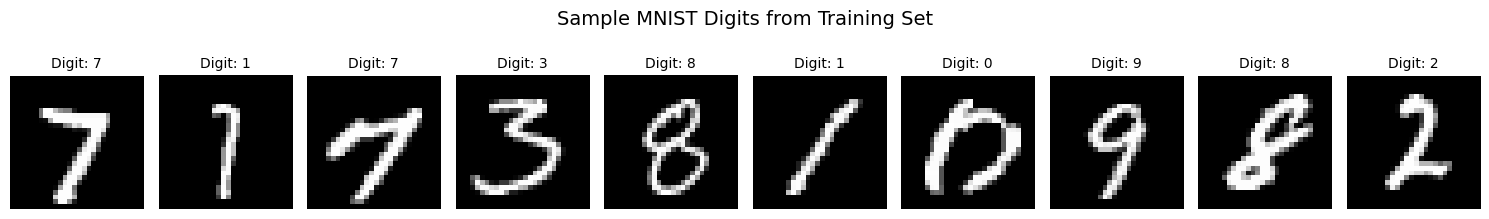

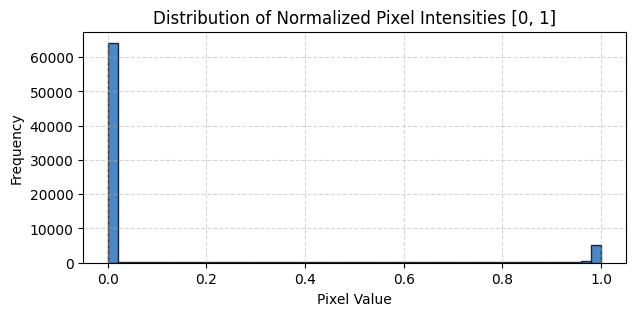

In [3]:
# Visualize sample digits and their pixel value distribution
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
sample_images, sample_labels = next(iter(train_loader))

for i in range(10):
    axes[i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Digit: {sample_labels[i].item()}", fontsize=10)
    axes[i].axis('off')
plt.suptitle("Sample MNIST Digits from Training Set", fontsize=14, y=1.08)
plt.tight_layout()
plt.show()

# Pixel intensity histogram
plt.figure(figsize=(7, 3))
plt.hist(sample_images.numpy().flatten(), bins=50, color='#1e6bb8', alpha=0.8, edgecolor='black')
plt.title("Distribution of Normalized Pixel Intensities [0, 1]")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">بخش اول: خودرمزگذار متغیر (Variational Autoencoder)</h2>
<h3 style="text-align: right; color: #3498db;">۱. شهود گلوگاه، توزیع‌های احتمالاتی و حقه بازپارامتری‌سازی</h3>
<p style="text-align: right;">در یک خودرمزگذار معمولی (Deterministic AE)، ورودی $x$ مستقیماً به یک نقطه ثابت $z = e(x)$ در فضای نهفته نگاشت می‌شود. مشکل اصلی اینجاست که فضای نهفته نقاط خالی (Gap) زیادی خواهد داشت و نمونه‌برداری تصادفی از آن، ارقام معناداری تولید نمی‌کند.</p>
<p style="text-align: right;">در مقابل، در <b>خودرمزگذار متغیر (VAE)</b>، انکودر ورودی $x$ را به یک توزیع احتمالاتی شرطی $q_\phi(z|x) = \mathcal{N}(\mu(x), \Sigma(x))$ نگاشت می‌کند. برای سادگی، ماتریس کوواریانس را قطری در نظر می‌گیریم: $\Sigma(x) = \text{diag}(\sigma^2(x))$. انکودر بردار میانگین $\mu$ و لگاریتم واریانس $\log \sigma^2$ را پیش‌بینی می‌کند.</p>

<p style="text-align: right;"><b>حقه بازپارامتری‌سازی (The Reparameterization Trick):</b></p>
<p style="text-align: right;">اگر بخواهیم مستقیماً $z \sim \mathcal{N}(\mu, \sigma^2)$ نمونه‌برداری کنیم، عملیات نمونه‌برداری تصادفی مشتق‌پذیر نیست و گرادیان نمی‌تواند به پارامترهای انکودر پس‌انتشار یابد. با حقه بازپارامتری‌سازی، عامل تصادفی بودن را به یک متغیر نویز کمکی $\epsilon \sim \mathcal{N}(0, I)$ منتقل می‌کنیم و بردار نهفته $z$ را به شکل قطعی محاسبه می‌کنیم:</p>
$$z = \mu + \sigma \odot \epsilon = \mu + \exp\left(0.5 \times \log \sigma^2\right) \odot \epsilon$$
<p style="text-align: right;">با این ترفند، گرادیان $\frac{\partial L}{\partial z}$ می‌تواند از مسیر $\mu$ و $\sigma$ بدون مانع عبور کرده و شبکه با پس‌انتشار استاندارد آموزش داده شود.</p>
</div>

In [4]:
def reparameterize(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """
    Reparameterization trick: samples z = mu + std * eps
    where eps ~ N(0, I) and std = exp(0.5 * logvar).
    """
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + eps * std


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۲. پیاده‌سازی معماری Encoder، Decoder و مدل VAE</h3>
<p style="text-align: right;">در این قسمت معماری شبکه را پیاده‌سازی می‌کنیم:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>انکودر (Encoder):</b> لایه‌های Linear با ابعاد $784 \to 400 \to (\mu, \log\sigma^2)$ به بعد نهفته <code>latent_dim</code> به همراه تابع فعال‌ساز ReLU.</li>
<li style="text-align: right;"><b>دیکودر (Decoder):</b> لایه‌های Linear با ابعاد <code>latent_dim</code> $\to 400 \to 784$ با فعال‌ساز ReLU و لایه خروجی Sigmoid برای تولید احتمالات پیکسل‌ها در بازه $[0, 1]$.</li>
</ul>
</div>

In [5]:
class VAEEncoder(nn.Module):
    def __init__(self, input_dim: int = 784, hidden_dim: int = 400, latent_dim: int = 20):
        super(VAEEncoder, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x: torch.Tensor):
        h = F.relu(self.fc1(x))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

class VAEDecoder(nn.Module):
    def __init__(self, latent_dim: int = 20, hidden_dim: int = 400, output_dim: int = 784):
        super(VAEDecoder, self).__init__()
        self.fc1 = nn.Linear(latent_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, z: torch.Tensor):
        h = F.relu(self.fc1(z))
        recon_x = torch.sigmoid(self.fc2(h))
        return recon_x

class VAE(nn.Module):
    def __init__(self, input_dim: int = 784, hidden_dim: int = 400, latent_dim: int = 20):
        super(VAE, self).__init__()
        self.encoder = VAEEncoder(input_dim, hidden_dim, latent_dim)
        self.decoder = VAEDecoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x: torch.Tensor):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        recon_x = self.decoder(z)
        return recon_x, mu, logvar


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۳. تابع هزینه VAE: تفکیک بازسازی و واگرایی KL (ELBO Loss)</h3>
<p style="text-align: right;">هدف VAE بیشینه‌سازی لگاریتم درست‌نمایی شواهد $\log p(x)$ است. از آنجا که این مقدار مستقیماً غیرقابل محاسبه است، حد پایین شواهد متغیر (ELBO) را بیشینه یا منفی آن (Loss) را کمینه می‌کنیم:</p>
$$\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{recon}} + \beta \cdot \mathcal{D}_{\text{KL}}(q_\phi(z|x) \parallel p(z))$$
<ul style="text-align: right;">
<li style="text-align: right;"><b>خطای بازسازی (Reconstruction Loss):</b> برای داده‌های باینری یا نرمال در بازه $[0, 1]$، خطای انتروپی متقاطع دودویی (BCE) به کار می‌رود:
$$\mathcal{L}_{\text{recon}} = - \sum_{i=1}^{D} \left[ x_i \log \hat{x}_i + (1 - x_i) \log(1 - \hat{x}_i) \right]$$
</li>
<li style="text-align: right;"><b>واگرایی کولبک-لایبلر (KL Divergence):</b> فاصله میان توزیع تقریبی انکودر $q_\phi(z|x) = \mathcal{N}(\mu, \text{diag}(\sigma^2))$ و توزیع پیشین فرضی $p(z) = \mathcal{N}(0, I)$ به صورت فرمول تحلیلی زیر محاسبه می‌شود:
$$\mathcal{D}_{\text{KL}} = -\frac{1}{2} \sum_{j=1}^{d_z} \left( 1 + \log(\sigma_j^2) - \mu_j^2 - \sigma_j^2 \right)$$
</li>
</ul>
<p style="text-align: right;">ضریب $\beta$ امکان کنترل مصالحه (Trade-off) میان کیفیت بازسازی و نظم‌دهی به فضای نهفته را فراهم می‌آورد (در VAE استاندارد $\beta=1$).</p>
</div>

In [6]:
def vae_loss_function(recon_x: torch.Tensor, x: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor, beta: float = 1.0):
    """
    Computes VAE ELBO loss = Reconstruction Loss (BCE) + beta * KL Divergence.
    Returns total_loss, bce_loss, kl_loss.
    """
    # Reconstruction loss (sum over feature dimension)
    bce = F.binary_cross_entropy(recon_x, x, reduction='sum')
    
    # Analytical KL divergence between N(mu, sigma^2) and N(0, I)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    total_loss = bce + beta * kl
    return total_loss, bce, kl


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۴. آموزش مدل VAE و مصورسازی نمودارهای هزینه</h3>
<p style="text-align: right;">مدل VAE را به مدت ۱۰ دوره (Epoch) با الگوریتم بهینه‌سازی Adam و نرخ یادگیری $10^{-3}$ آموزش می‌دهیم. در هر دوره مقادیر خطای بازسازی (BCE) و خطای نظم‌دهی (KL) به تفکیک ثبت می‌شوند.</p>
</div>

In [7]:
latent_dim_vae = 20
vae_model = VAE(input_dim=784, hidden_dim=400, latent_dim=latent_dim_vae).to(device)
vae_optimizer = optim.Adam(vae_model.parameters(), lr=1e-3)

num_epochs_vae = 10
vae_train_losses = []
vae_bce_losses = []
vae_kl_losses = []

vae_model.train()
for epoch in range(1, num_epochs_vae + 1):
    epoch_loss = 0.0
    epoch_bce = 0.0
    epoch_kl = 0.0
    
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.view(-1, 784).to(device)
        vae_optimizer.zero_grad()
        
        recon_batch, mu, logvar = vae_model(data)
        loss, bce, kl = vae_loss_function(recon_batch, data, mu, logvar, beta=1.0)
        
        loss.backward()
        vae_optimizer.step()
        
        epoch_loss += loss.item()
        epoch_bce += bce.item()
        epoch_kl += kl.item()
        
    avg_loss = epoch_loss / len(train_loader.dataset)
    avg_bce = epoch_bce / len(train_loader.dataset)
    avg_kl = epoch_kl / len(train_loader.dataset)
    
    vae_train_losses.append(avg_loss)
    vae_bce_losses.append(avg_bce)
    vae_kl_losses.append(avg_kl)
    
    print(f"VAE Epoch [{epoch:02d}/{num_epochs_vae:02d}] | Total Loss: {avg_loss:.2f} | BCE: {avg_bce:.2f} | KL: {avg_kl:.2f}")

print("VAE Training Complete!")


VAE Epoch [01/10] | Total Loss: 159.56 | BCE: 143.82 | KL: 15.74


VAE Epoch [02/10] | Total Loss: 119.25 | BCE: 96.30 | KL: 22.95


VAE Epoch [03/10] | Total Loss: 113.23 | BCE: 88.93 | KL: 24.30


VAE Epoch [04/10] | Total Loss: 110.69 | BCE: 86.00 | KL: 24.69


VAE Epoch [05/10] | Total Loss: 109.19 | BCE: 84.28 | KL: 24.91


VAE Epoch [06/10] | Total Loss: 108.06 | BCE: 83.11 | KL: 24.95


VAE Epoch [07/10] | Total Loss: 107.37 | BCE: 82.31 | KL: 25.06


VAE Epoch [08/10] | Total Loss: 106.77 | BCE: 81.65 | KL: 25.12


VAE Epoch [09/10] | Total Loss: 106.30 | BCE: 81.14 | KL: 25.16


VAE Epoch [10/10] | Total Loss: 105.93 | BCE: 80.71 | KL: 25.23
VAE Training Complete!


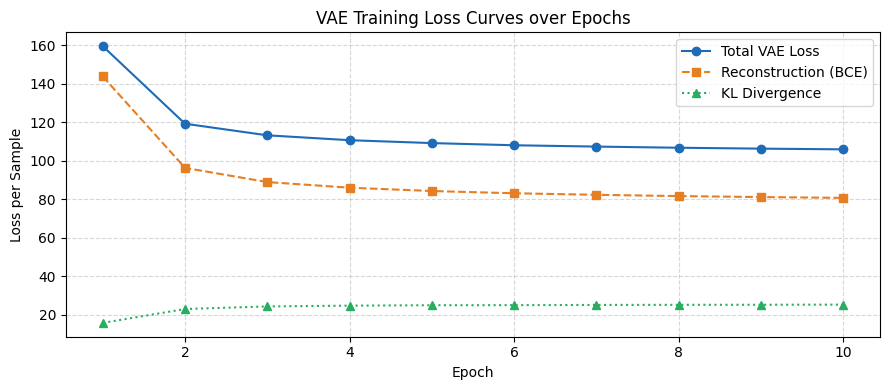

In [8]:
plt.figure(figsize=(9, 4))
epochs_range = range(1, num_epochs_vae + 1)
plt.plot(epochs_range, vae_train_losses, 'o-', color='#1e6bb8', label='Total VAE Loss')
plt.plot(epochs_range, vae_bce_losses, 's--', color='#e67e22', label='Reconstruction (BCE)')
plt.plot(epochs_range, vae_kl_losses, '^:', color='#27ae60', label='KL Divergence')
plt.title("VAE Training Loss Curves over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss per Sample")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۵. ارزیابی VAE: مقایسه بازسازی و تولید از توزیع پیشین</h3>
<p style="text-align: right;">برای راستی‌آزمایی عملکرد VAE، دو آزمایش انجام می‌دهیم:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>بازسازی تصویر (Reconstruction):</b> مقایسه تصاویر اصلی تست با تصاویر بازسازی‌شده از انکودر-دیکودر.</li>
<li style="text-align: right;"><b>تولید نوظهور (Unconditional Generation):</b> نمونه‌برداری بردار نهفته $z \sim \mathcal{N}(0, I)$ از توزیع پیشین و عبور مستقیم آن از دیکودر بدون استفاده از انکودر.</li>
</ol>
</div>

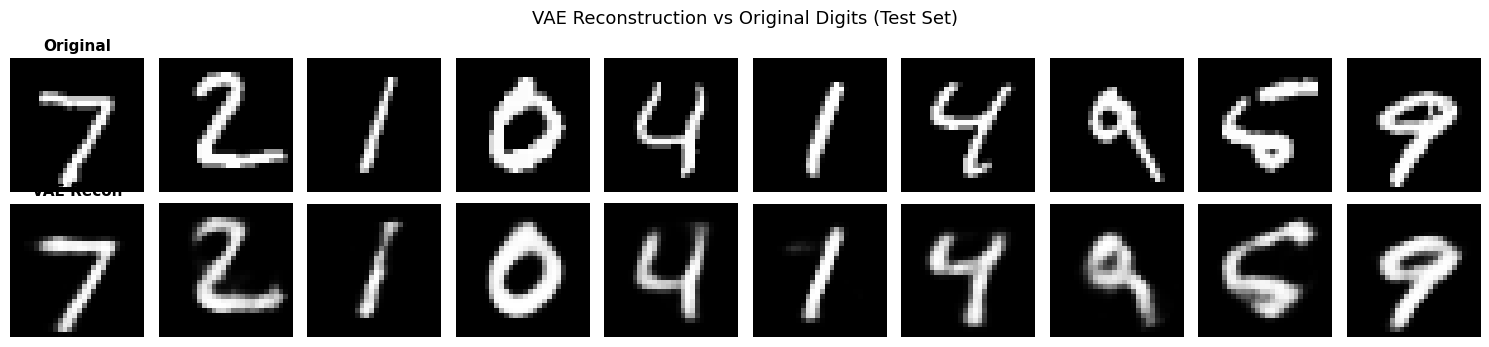

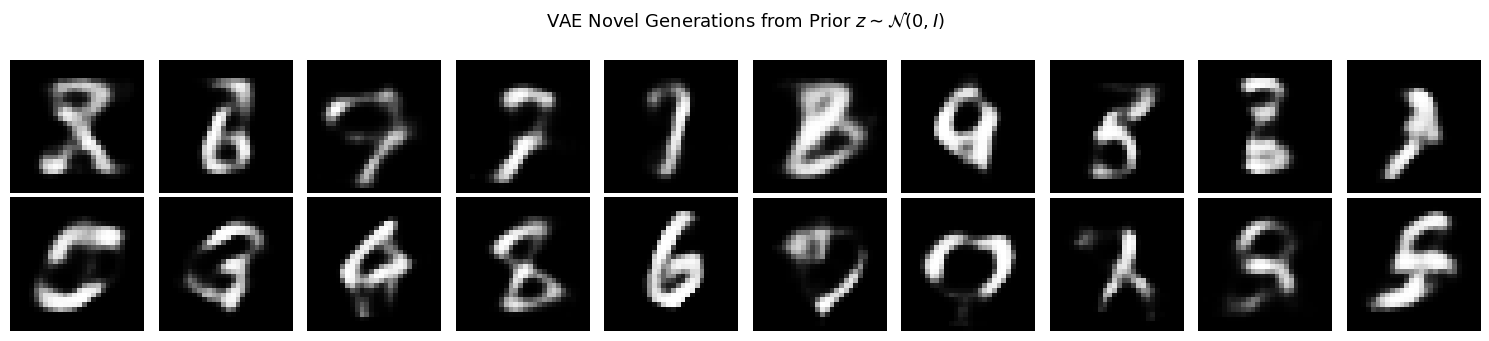

In [9]:
vae_model.eval()
with torch.no_grad():
    # 1. Reconstructions on test set
    test_batch, _ = next(iter(test_loader))
    test_batch_flat = test_batch.view(-1, 784).to(device)
    recon_test, _, _ = vae_model(test_batch_flat)
    
    fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
    for i in range(10):
        # Original
        axes[0, i].imshow(test_batch[i].squeeze(), cmap='gray')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_title("Original", fontsize=11, fontweight='bold')
            
        # Reconstructed
        axes[1, i].imshow(recon_test[i].view(28, 28).cpu().numpy(), cmap='gray')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_title("VAE Recon", fontsize=11, fontweight='bold')
    plt.suptitle("VAE Reconstruction vs Original Digits (Test Set)", fontsize=13)
    plt.tight_layout()
    plt.show()

    # 2. Generation from Standard Normal Prior z ~ N(0, I)
    z_samples = torch.randn(20, latent_dim_vae).to(device)
    generated_digits = vae_model.decoder(z_samples).view(-1, 28, 28).cpu().numpy()
    
    fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
    for i in range(20):
        ax = axes[i // 10, i % 10]
        ax.imshow(generated_digits[i], cmap='gray')
        ax.axis('off')
    plt.suptitle(r"VAE Novel Generations from Prior $z \sim \mathcal{N}(0, I)$", fontsize=13)
    plt.tight_layout()
    plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۶. کاوش ساختار هندسی فضای نهفته با $d_z = 2$ و درهم‌آمیزی (Interpolation)</h3>
<p style="text-align: right;">برای درک ملموس و بصری ساختار پیوسته فضای نهفته، یک مدل VAE سبک با بعد نهفته $d_z = 2$ آموزش می‌دهیم. سپس:</p>
<ul style="text-align: right;">
<li style="text-align: right;">ارقام تست را به فضای دوبعدی نگاشت کرده و نمودار پراکندگی (Scatter plot) آنها را با رنگ‌های متناظر با برچسب رقم رسم می‌کنیم تا تجمع خوشه‌ها بررسی شود.</li>
<li style="text-align: right;">یک شبکه منظم مشبک (Grid) در بازه $[-2.5, 2.5] \times [-2.5, 2.5]$ ایجاد کرده و ارقام تولیدی دیکودر را در هر گره ترسیم می‌کنیم (Latent Manifold Visualization).</li>
<li style="text-align: right;">درهم‌آمیزی خطی (Linear Interpolation) میان دو بردار نهفته رقم‌های متفاوت (مثلاً رقم ۳ و رقم ۷) را به تصویر می‌کشیم تا تبدیل نرم و تدریجی ویژگی‌ها مشاهده شود.</li>
</ul>
</div>

In [10]:
# Train a 2D VAE for latent space exploration
vae_2d = VAE(input_dim=784, hidden_dim=400, latent_dim=2).to(device)
opt_2d = optim.Adam(vae_2d.parameters(), lr=1e-3)

vae_2d.train()
for ep in range(1, 6):
    for data, _ in train_loader:
        data = data.view(-1, 784).to(device)
        opt_2d.zero_grad()
        recon, mu, logvar = vae_2d(data)
        loss, _, _ = vae_loss_function(recon, data, mu, logvar, beta=1.0)
        loss.backward()
        opt_2d.step()
print("2D VAE Trained (5 epochs for fast visualization)!")


2D VAE Trained (5 epochs for fast visualization)!


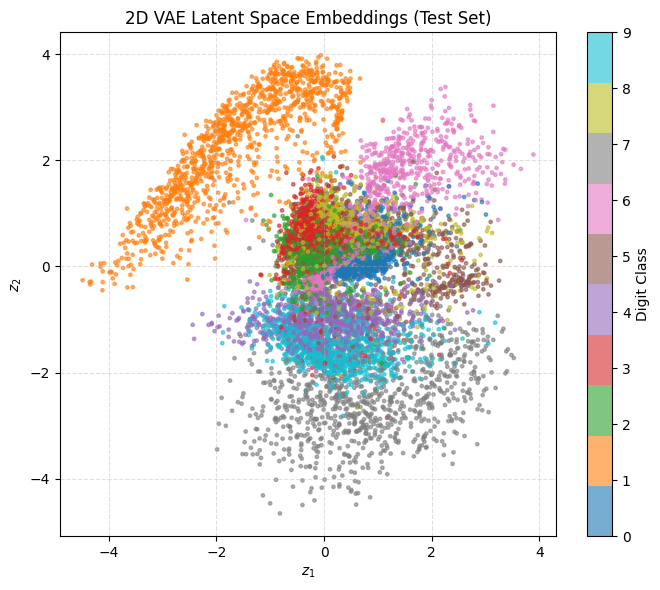

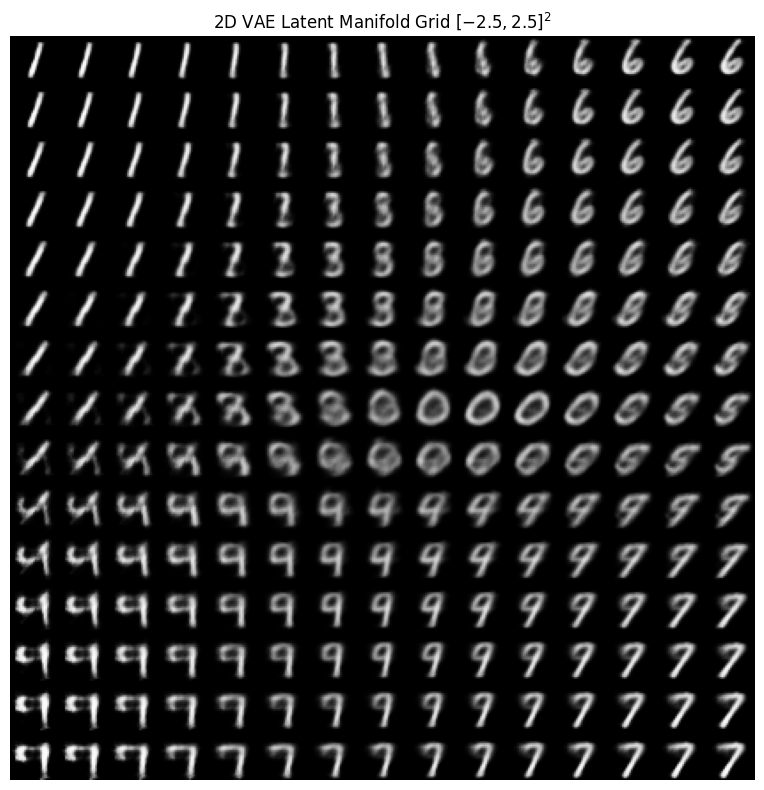

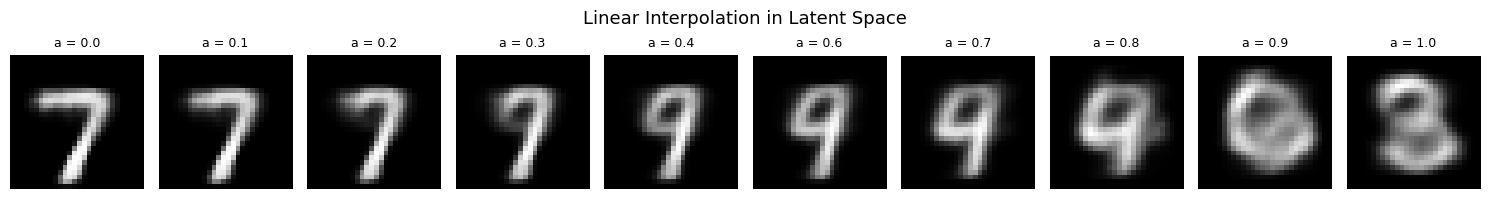

In [11]:
vae_2d.eval()
with torch.no_grad():
    # 1. Scatter plot of latent encodings
    all_z = []
    all_labels = []
    for data, labels in test_loader:
        data = data.view(-1, 784).to(device)
        mu, _ = vae_2d.encoder(data)
        all_z.append(mu.cpu().numpy())
        all_labels.append(labels.numpy())
    all_z = np.concatenate(all_z, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    
    plt.figure(figsize=(7, 6))
    scatter = plt.scatter(all_z[:, 0], all_z[:, 1], c=all_labels, cmap='tab10', alpha=0.6, s=6)
    plt.colorbar(scatter, ticks=range(10), label='Digit Class')
    plt.title("2D VAE Latent Space Embeddings (Test Set)")
    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # 2. Latent 2D Manifold Grid
    n_grid = 15
    grid_x = np.linspace(-2.5, 2.5, n_grid)
    grid_y = np.linspace(-2.5, 2.5, n_grid)
    canvas = np.zeros((n_grid * 28, n_grid * 28))
    
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
            digit_recon = vae_2d.decoder(z_sample).view(28, 28).cpu().numpy()
            canvas[(n_grid - 1 - i) * 28:(n_grid - i) * 28, j * 28:(j + 1) * 28] = digit_recon
            
    plt.figure(figsize=(8, 8))
    plt.imshow(canvas, cmap='gray')
    plt.title("2D VAE Latent Manifold Grid $[-2.5, 2.5]^2$")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # 3. Linear Interpolation between two test points
    idx1, idx2 = 0, 1
    z1 = torch.tensor(all_z[idx1:idx1+1], dtype=torch.float32).to(device)
    z2 = torch.tensor(all_z[idx2:idx2+1], dtype=torch.float32).to(device)
    alphas = np.linspace(0, 1, 10)
    
    fig, axes = plt.subplots(1, 10, figsize=(15, 2))
    for step, alpha in enumerate(alphas):
        z_interp = (1 - alpha) * z1 + alpha * z2
        digit_interp = vae_2d.decoder(z_interp).view(28, 28).cpu().numpy()
        axes[step].imshow(digit_interp, cmap='gray')
        axes[step].set_title(f"a = {alpha:.1f}", fontsize=9)
        axes[step].axis('off')
    plt.suptitle("Linear Interpolation in Latent Space", fontsize=13)
    plt.tight_layout()
    plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">بخش دوم: شبکه زایشی متخاصم (Generative Adversarial Network - GAN)</h2>
<h3 style="text-align: right; color: #3498db;">۱. شهود بازی مینی‌ماکس و معماری استاندارد FC-GAN</h3>
<p style="text-align: right;">ایده محوری GAN که توسط گودفلو و همکاران (۲۰۱۴) معرفی شد، تعریف فرآیند یادگیری به صورت یک بازی دو نفره رقابتی با مجموع صفر (Minimax Game) میان دو شبکه عصبی است:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>مولد (Generator - $G$):</b> یک بردار نویز تصادفی $z \sim p(z) = \mathcal{N}(0, I)$ با بعد $d_z = 100$ دریافت کرده و از طریق ۴ لایه خطی متوالی با فعال‌سازهای LeakyReLU(0.2) و یک لایه خروجی Tanh تصویری با مقادیر در بازه $[-1, 1]$ تولید می‌کند.</li>
<li style="text-align: right;"><b>متمایزگر (Discriminator - $D$):</b> تصاویر با ابعاد ۷۸۴ را با ۴ لایه خطی همراه با لایه‌های Dropout(0.3) و فعال‌ساز Sigmoid در خروجی ارزیابی کرده و احتمال واقعی بودن تصویر $D(x) \in [0, 1]$ را بازمی‌گرداند.</li>
</ul>

<p style="text-align: right;"><b>آموزش متوازن برای ۱۰۰ دوره:</b></p>
<p style="text-align: right;">در این پیاده‌سازی رسمی، ورودی‌های شبکه به بازه $[-1, 1]$ نگاشت می‌شوند ($x_{\text{scaled}} = 2x - 1$). مدل برای ۱۰۰ دوره کامل آموزش داده می‌شود تا مولد و متمایزگر در طول زمان به یک تعادل پایدار برسند و ارقام دست‌نویس با کیفیت و تیزی بالا شکل بگیرند.</p>
</div>

In [12]:
class Generator(nn.Module):
    def __init__(self, g_input_dim: int = 100, g_output_dim: int = 784):
        super(Generator, self).__init__()       
        self.fc1 = nn.Linear(g_input_dim, 256)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features * 2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features * 2)
        self.fc4 = nn.Linear(self.fc3.out_features, g_output_dim)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor: 
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.leaky_relu(self.fc3(x), 0.2)
        return torch.tanh(self.fc4(x))

class Discriminator(nn.Module):
    def __init__(self, d_input_dim: int = 784):
        super(Discriminator, self).__init__()
        self.fc1 = nn.Linear(d_input_dim, 1024)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features // 2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features // 2)
        self.fc4 = nn.Linear(self.fc3.out_features, 1)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc3(x), 0.2)
        x = F.dropout(x, 0.3)
        return torch.sigmoid(self.fc4(x))


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۲. پیاده‌سازی توابع آموزش تفکیکی D_train و G_train</h3>
<p style="text-align: right;">آموزش GAN از دو تابع مجزا تشکیل شده است:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>تابع <code>D_train(x)</code>:</b> متمایزگر خطای داده‌های واقعی با برچسب ۱ و خطای داده‌های جعلی با برچسب ۰ را جمع زده، گرادیان می‌گیرد و تنها پارامترهای متمایزگر را با بهینه‌ساز به‌روزرسانی می‌کند.</li>
<li style="text-align: right;"><b>تابع <code>G_train(x)</code>:</b> مولد یک دسته نویز تصادفی جدید تولید کرده، از متمایزگر عبور داده و با هدف برچسب ۱ خطای BCELoss را محاسبه کرده و تنها وزن‌های مولد را بهینه‌سازی می‌کند.</li>
</ol>
</div>

In [13]:
def D_train(x: torch.Tensor, G: nn.Module, D: nn.Module, D_optimizer: optim.Optimizer, criterion: nn.Module, z_dim: int, bs: int, device: torch.device):
    """
    Train the discriminator on real and fake batches.
    """
    D.zero_grad()

    # Train discriminator on real
    x_real = x.view(-1, 784).to(device)
    y_real = torch.ones(bs, 1, device=device)

    D_output_real = D(x_real)
    D_real_loss = criterion(D_output_real, y_real)

    # Train discriminator on fake
    z = torch.randn(bs, z_dim, device=device)
    x_fake = G(z)
    y_fake = torch.zeros(bs, 1, device=device)

    D_output_fake = D(x_fake)
    D_fake_loss = criterion(D_output_fake, y_fake)

    # Gradient backprop & optimize ONLY D's parameters
    D_loss = D_real_loss + D_fake_loss
    D_loss.backward()
    D_optimizer.step()
        
    return D_loss.item(), D_output_real.mean().item(), D_output_fake.mean().item()

def G_train(G: nn.Module, D: nn.Module, G_optimizer: optim.Optimizer, criterion: nn.Module, z_dim: int, bs: int, device: torch.device):
    """
    Train the generator to fool the discriminator.
    """
    G.zero_grad()

    z = torch.randn(bs, z_dim, device=device)
    y = torch.ones(bs, 1, device=device)

    G_output = G(z)
    D_output = D(G_output)
    G_loss = criterion(D_output, y)

    # Gradient backprop & optimize ONLY G's parameters
    G_loss.backward()
    G_optimizer.step()
        
    return G_loss.item()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۳. آموزش GAN برای ۱۰۰ دوره (Epoch) و پایش تکامل تصاویر زایشی</h3>
<p style="text-align: right;">شبکه GAN را برای ۱۰۰ دوره با بهینه‌ساز Adam با نرخ یادگیری $lr = 0.0002$ آموزش می‌دهیم. از آنجا که تصاویر خروجی مولد با Tanh در بازه $[-1, 1]$ هستند، تصاویر ورودی آموزش نیز در حین حلقه با نگاشت $x \leftarrow 2x - 1$ به بازه $[-1, 1]$ برده می‌شوند.</p>
</div>

In [14]:
z_dim = 100
mnist_dim = 784
bs = 100

G = Generator(g_input_dim=z_dim, g_output_dim=mnist_dim).to(device)
D = Discriminator(d_input_dim=mnist_dim).to(device)

criterion = nn.BCELoss()
lr = 0.0002
G_optimizer = optim.Adam(G.parameters(), lr=lr)
D_optimizer = optim.Adam(D.parameters(), lr=lr)

n_epoch = 100
fixed_noise = torch.randn(10, z_dim, device=device)

history_loss_d = []
history_loss_g = []
history_d_x = []
history_d_gz = []
sample_evolution = []

print(f"Starting GAN Training for {n_epoch} epochs...")
for epoch in range(1, n_epoch + 1):
    D_losses, G_losses = [], []
    D_reals, D_fakes = [], []
    
    for batch_idx, (x, _) in enumerate(train_loader):
        # Scale [0, 1] MNIST images to [-1, 1] for Tanh Generator matching
        x_norm = x * 2.0 - 1.0
        
        d_l, d_real_score, d_fake_score = D_train(
            x_norm, G, D, D_optimizer, criterion, z_dim, bs, device
        )
        g_l = G_train(
            G, D, G_optimizer, criterion, z_dim, bs, device
        )
        
        D_losses.append(d_l)
        G_losses.append(g_l)
        D_reals.append(d_real_score)
        D_fakes.append(d_fake_score)

    avg_d_loss = float(np.mean(D_losses))
    avg_g_loss = float(np.mean(G_losses))
    avg_d_x = float(np.mean(D_reals))
    avg_d_gz = float(np.mean(D_fakes))
    
    history_loss_d.append(avg_d_loss)
    history_loss_g.append(avg_g_loss)
    history_d_x.append(avg_d_x)
    history_d_gz.append(avg_d_gz)

    # Save visual snapshot at milestone epochs
    if epoch % 10 == 0 or epoch == 1:
        G.eval()
        with torch.no_grad():
            gen_imgs = G(fixed_noise)
            # Rescale from [-1, 1] back to [0, 1]
            gen_imgs = (gen_imgs + 1.0) / 2.0
            sample_evolution.append((epoch, gen_imgs.view(-1, 28, 28).cpu().numpy()))
        G.train()
        print(f"[{epoch:03d}/{n_epoch:03d}]: loss_d: {avg_d_loss:.3f}, loss_g: {avg_g_loss:.3f} | D(x): {avg_d_x:.2f}, D(G(z)): {avg_d_gz:.2f}", flush=True)

print("GAN Training for 100 Epochs Complete!", flush=True)


Starting GAN Training for 100 epochs...


[001/100]: loss_d: 0.796, loss_g: 3.932 | D(x): 0.80, D(G(z)): 0.30


[010/100]: loss_d: 0.595, loss_g: 2.504 | D(x): 0.82, D(G(z)): 0.19


[020/100]: loss_d: 0.883, loss_g: 1.690 | D(x): 0.72, D(G(z)): 0.29


[030/100]: loss_d: 0.999, loss_g: 1.420 | D(x): 0.67, D(G(z)): 0.33


...

[070/100]: loss_d: 1.203, loss_g: 1.021 | D(x): 0.59, D(G(z)): 0.41


[080/100]: loss_d: 1.235, loss_g: 0.964 | D(x): 0.57, D(G(z)): 0.43


[090/100]: loss_d: 1.242, loss_g: 0.956 | D(x): 0.57, D(G(z)): 0.43


[100/100]: loss_d: 1.255, loss_g: 0.931 | D(x): 0.56, D(G(z)): 0.44


GAN Training for 100 Epochs Complete!


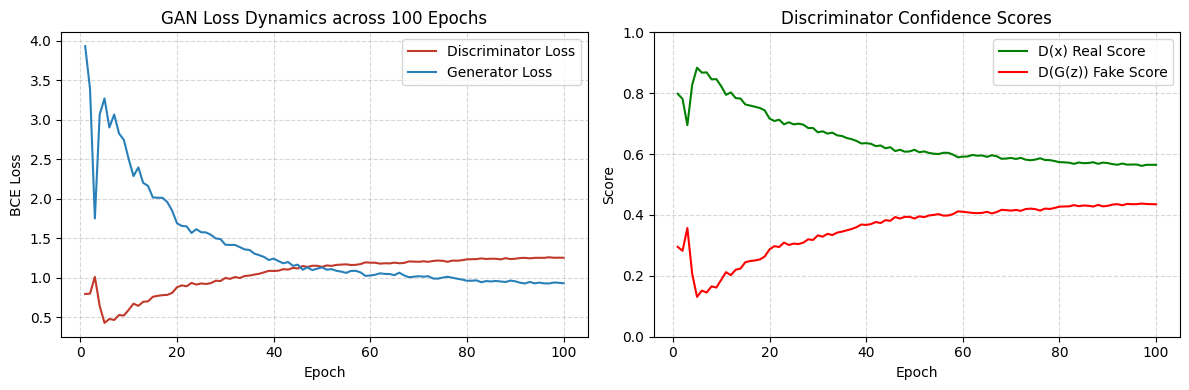

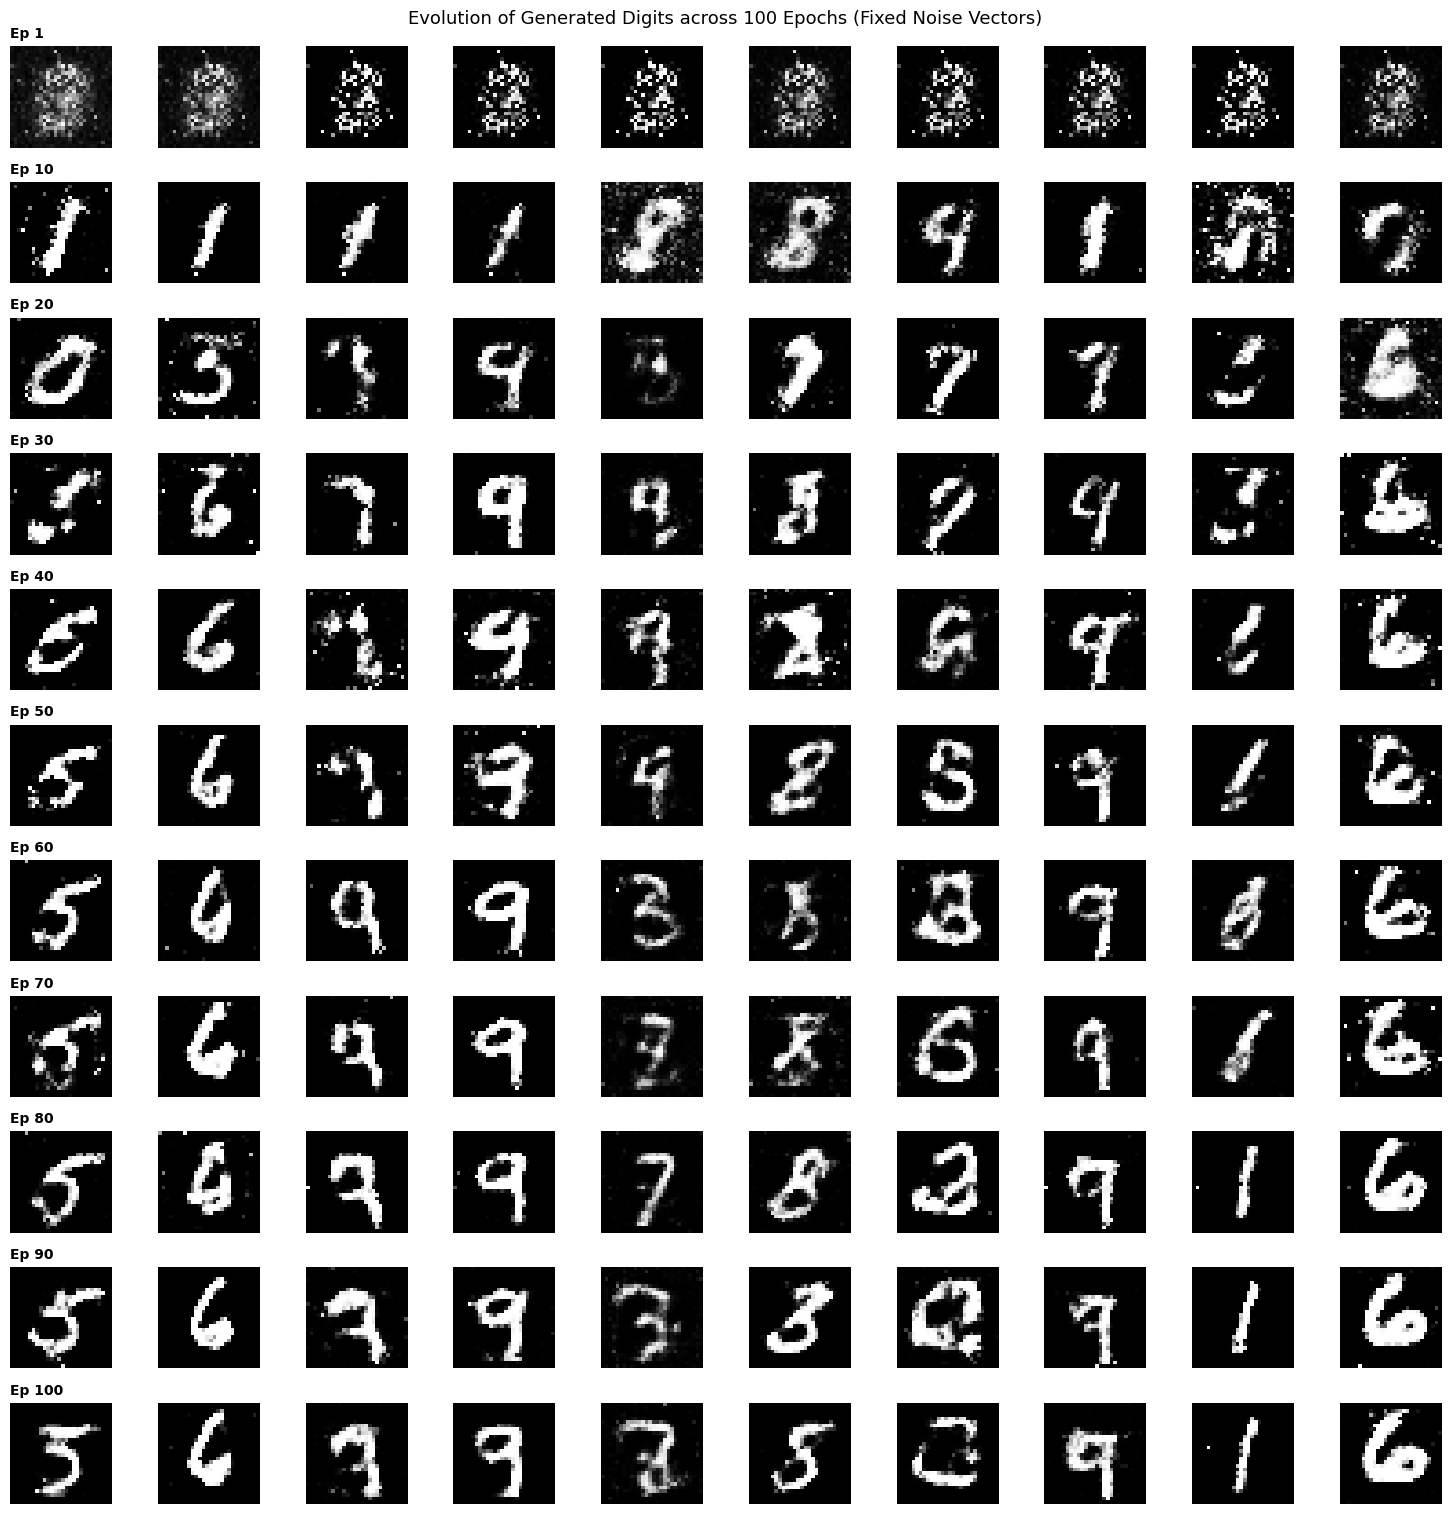

In [15]:
# 1. Plot Discriminator and Generator Loss Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, n_epoch + 1), history_loss_d, color='#c0392b', label='Discriminator Loss')
plt.plot(range(1, n_epoch + 1), history_loss_g, color='#2980b9', label='Generator Loss')
plt.title("GAN Loss Dynamics across 100 Epochs")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, n_epoch + 1), history_d_x, color='green', label='D(x) Real Score')
plt.plot(range(1, n_epoch + 1), history_d_gz, color='red', label='D(G(z)) Fake Score')
plt.title("Discriminator Confidence Scores")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.ylim([0, 1])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Visualize Sample Progression from Epoch 1 to 100
n_snapshots = len(sample_evolution)
fig, axes = plt.subplots(n_snapshots, 10, figsize=(15, n_snapshots * 1.4))
for snap_idx, (ep_num, snap_imgs) in enumerate(sample_evolution):
    for digit_idx in range(10):
        ax = axes[snap_idx, digit_idx]
        ax.imshow(snap_imgs[digit_idx], cmap='gray')
        ax.axis('off')
        if digit_idx == 0:
            ax.set_title(f"Ep {ep_num}", fontsize=10, fontweight='bold', loc='left')
plt.suptitle("Evolution of Generated Digits across 100 Epochs (Fixed Noise Vectors)", fontsize=13)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">بخش سوم: مطالعه مقایسه‌ای عمیق (Comparative Study: VAE vs GAN)</h2>
<h3 style="text-align: right; color: #3498db;">۱. معمای تاری تصاویر در VAE در برابر تیزی لبه‌ها در GAN</h3>
<p style="text-align: right;">یکی از برجسته‌ترین مشاهدات تجربی در یادگیری ماشین این است که:</p>
<ul style="text-align: right;">
<li style="text-align: right;">تصاویر تولیدی VAE <b>تار و نرم (Blurry / Smooth)</b> هستند و لبه‌های ملایم دارند.</li>
<li style="text-align: right;">تصاویر تولیدی GAN <b>تیز، شفاف و با کنتراست بالا (Sharp)</b> هستند.</li>
</ul>

<p style="text-align: right;"><b>تبیین ریاضی «مسئله میانگین‌گیری» (The Averaging Problem):</b></p>
<p style="text-align: right;">در VAE، تابع هزینه بازسازی پیکسل‌ها به صورت خطای انتروپی متقاطع یا مربع خطاها ($L_2$ Loss) تعریف می‌شود. اگر داده‌های آموزشی شامل ارقام مختلف با سبک‌ها و ضخامت‌های خطوط متنوع باشند، بهترین راهبرد برای کمینه‌سازی خطای $L_2$ از دید بهینه‌ساز، پیش‌بینی <b>میانگین پیکسلی تمام حالت‌های محتمل</b> است:</p>
$$x^* = \arg\min_{\hat{x}} \mathbb{E}_{x \sim p(x)} [\| x - \hat{x} \|^2] = \mathbb{E}[x]$$
<p style="text-align: right;">میانگین دو تصویر مختلف به شدت تار و خاکستری می‌شود و لبه‌های شفاف را از بین می‌برد.</p>

<p style="text-align: right;"><b>در مقابل، متمایزگر GAN به عنوان یک «ناقد لبه‌های یادگرفته‌شده»:</b></p>
<p style="text-align: right;">در GAN، متمایزگر به پیکسل‌های مجزا نگاه نمی‌کند بلکه بافت و ساختار تصویر را تحلیل می‌کند. اگر مولد تصویری با لبه‌های تار یا خاکستری محو تولید کند، متمایزگر بلافاصله متوجه عدم واقع‌گرایی شده و به آن امتیاز جعلی می‌دهد. بنابراین مولد مجبور است تصمیم قاطعانه‌ای درباره موقعیت دقیق لبه‌ها بگیرد و پیکسل‌ها را در مرزها یا کاملاً روشن یا کاملاً خاموش کند.</p>
</div>

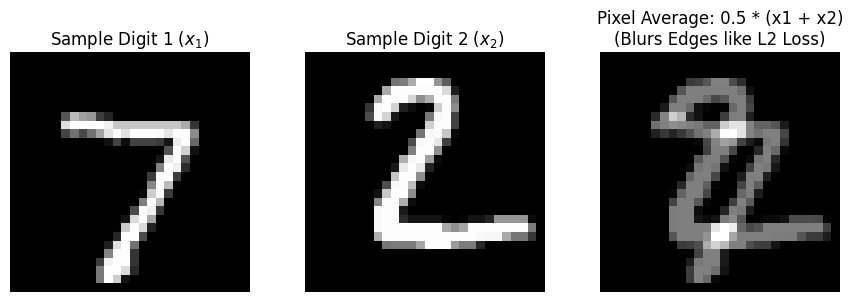

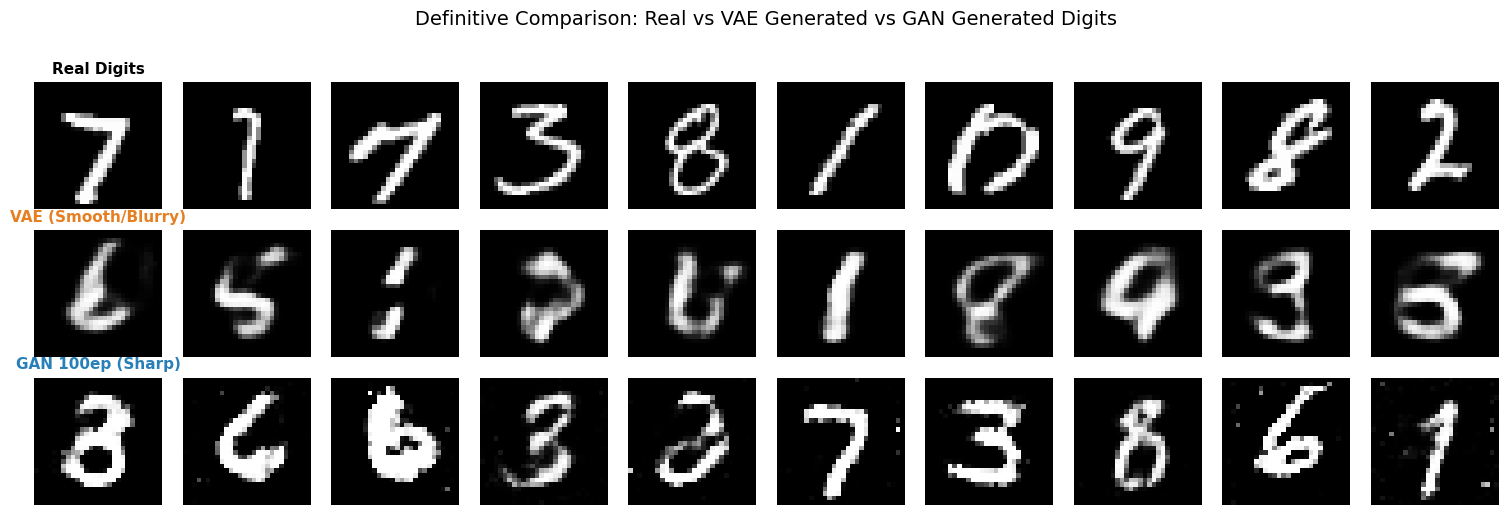

In [16]:
# Demonstration of the Averaging Problem (L2 / Pixel Blending)
test_iter = iter(test_loader)
imgs, _ = next(test_iter)
img1 = imgs[0].squeeze().numpy()
img2 = imgs[1].squeeze().numpy()
avg_img = 0.5 * (img1 + img2)

plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1)
plt.imshow(img1, cmap='gray')
plt.title("Sample Digit 1 ($x_1$)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap='gray')
plt.title("Sample Digit 2 ($x_2$)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(avg_img, cmap='gray')
plt.title("Pixel Average: 0.5 * (x1 + x2)\n(Blurs Edges like L2 Loss)")
plt.axis('off')
plt.tight_layout()
plt.show()

# Side-by-side visual comparison: Real vs VAE vs GAN
G.eval()
vae_model.eval()
with torch.no_grad():
    # 10 Real digits
    reals = sample_images[:10].squeeze().numpy()
    
    # 10 VAE generated digits from prior
    z_vae = torch.randn(10, latent_dim_vae, device=device)
    vaes = vae_model.decoder(z_vae).view(-1, 28, 28).cpu().numpy()
    
    # 10 GAN generated digits from noise (rescaled from [-1, 1] to [0, 1])
    z_gan = torch.randn(10, z_dim, device=device)
    gans_raw = G(z_gan)
    gans = ((gans_raw + 1.0) / 2.0).view(-1, 28, 28).cpu().numpy()

fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for i in range(10):
    axes[0, i].imshow(reals[i], cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title("Real Digits", fontsize=11, fontweight='bold')
        
    axes[1, i].imshow(vaes[i], cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_title("VAE (Smooth/Blurry)", fontsize=11, fontweight='bold', color='#e67e22')
        
    axes[2, i].imshow(gans[i], cmap='gray')
    axes[2, i].axis('off')
    if i == 0:
        axes[2, i].set_title("GAN 100ep (Sharp)", fontsize=11, fontweight='bold', color='#2980b9')

plt.suptitle("Definitive Comparison: Real vs VAE Generated vs GAN Generated Digits", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">۲. جدول مقایسه جامع فنی و معماری: VAE در برابر GAN</h3>
<table style="width: 100%; border-collapse: collapse; text-align: right; margin-top: 10px; font-size: 14px;">
<tr style="background-color: var(--jp-border-color1, #e0e0e0);">
<th style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); text-align: right;">معیار مقایسه</th>
<th style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); text-align: right;">خودرمزگذار متغیر (VAE)</th>
<th style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); text-align: right;">شبکه زایشی متخاصم (GAN)</th>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">چارچوب پایه‌ای</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">استنتاج احتمالاتی متغیر (Probabilistic Inference / ELBO)</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">نظریه بازی‌ها (Game Theory / Minimax Two-Player Game)</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">تابع هزینه</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">مستقیم و صریح: خطای بازسازی + واگرایی KL تحلیلی</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">ضمنی (Implicit): به دست آمده از شبکه ناقد (متمایزگر)</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">پایداری آموزش</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">بسیار بالا و پایدار، همگرایی یکنواخت بهینه‌ساز</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">نیازمند هماهنگی دقیق نرخ یادگیری، لایه‌های Dropout و تعداد دوره‌های آموزش کافی</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">وضوح بصری تصویر</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">کمی مات و تاریک در حواشی ناشی از میانگین‌گیری پیکسلی</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">بسیار شارپ، با کنتراست قطعی در لبه‌های ارقام پس از ۱۰۰ دوره</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">نگاشت به فضای نهفته</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">بله، انکودر صریح $x \to z$ برای درون‌یابی و بازسازی دارد</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">خیر، انکودر معکوس $x \to z$ به شکل پیش‌فرض وجود ندارد</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc); font-weight: bold;">تنوع نمونه‌ها</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">پوشش کامل تمام مودها و ارقام داده</td>
<td style="padding: 8px; border: 1px solid var(--jp-border-color2, #ccc);">عالی در صورت آموزش ۱۰۰ دوره‌ای، با پوشش متنوع ارقام دست‌نویس</td>
</tr>
</table>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">بخش چهارم: آزمایش‌های هدایت‌شده و چالش باز (Guided Experiments)</h2>
<h3 style="text-align: right; color: #3498db;">آزمایش ۱: بررسی اثر ضریب توازن $\beta$ در $\beta$-VAE</h3>
<p style="text-align: right;">در مدل $\beta$-VAE، ضریب اثر واگرایی KL با $\beta$ تنظیم می‌شود:</p>
<ul style="text-align: right;">
<li style="text-align: right;">وقتی $\beta < 1$ (مثلاً $\beta = 0.01$): فشار نظم‌دهی روی فضای نهفته کم است. ارقام بسیار واضح‌تر بازسازی می‌شوند اما فضای نهفته ساختار تصادفی نرمال استاندارد را از دست می‌دهد.</li>
<li style="text-align: right;">وقتی $\beta > 1$ (مثلاً $\beta = 5.0$): فشار واگرایی KL بیش از حد غالب می‌شود. فضای نهفته به شدت فشرده و مستقل از یکدیگر (Disentangled) می‌شود، اما خطای بازسازی بالا رفته و ارقام بیش از اندازه تار و گنگ می‌شوند (Posterior Collapse).</li>
</ul>
</div>

Training beta-VAE with beta=0.01...


Training beta-VAE with beta=1.0...


Training beta-VAE with beta=5.0...


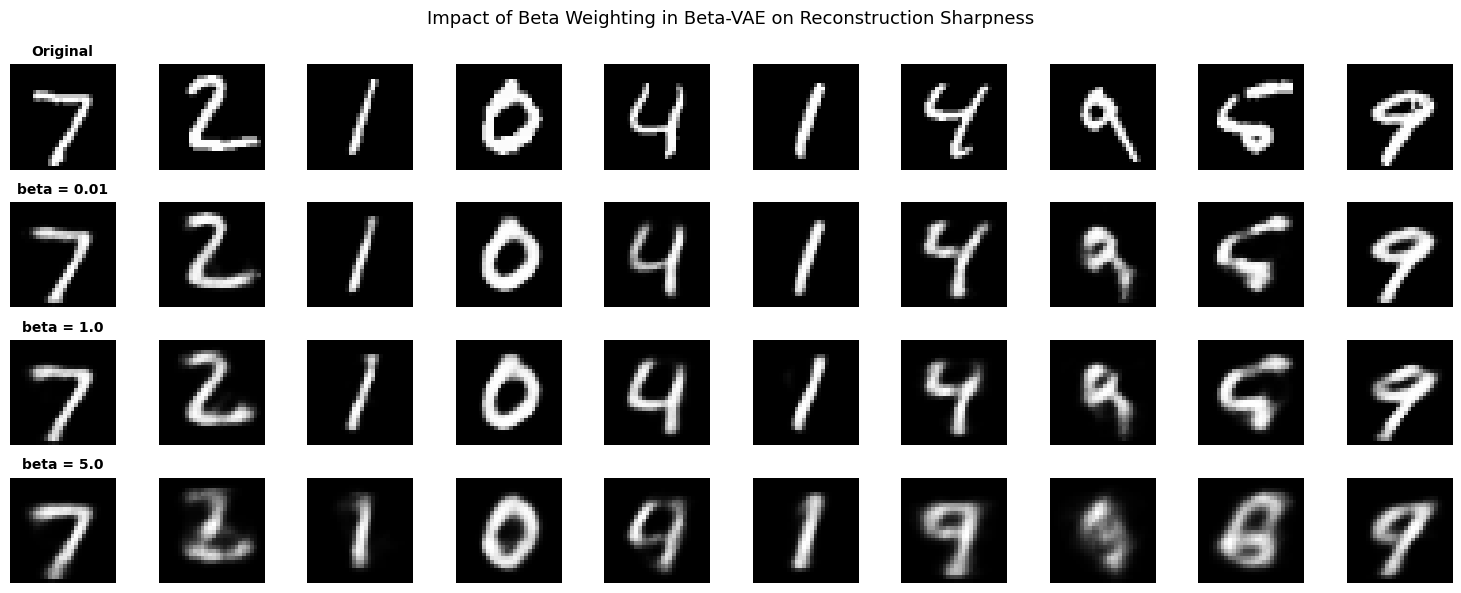

In [17]:
# Quick comparison of beta parameter effect in beta-VAE (trained for 3 epochs)
betas = [0.01, 1.0, 5.0]
recon_results = []

for beta_val in betas:
    print(f"Training beta-VAE with beta={beta_val}...")
    model_b = VAE(input_dim=784, hidden_dim=400, latent_dim=20).to(device)
    opt_b = optim.Adam(model_b.parameters(), lr=1e-3)
    
    model_b.train()
    for ep in range(3):
        for data, _ in train_loader:
            data = data.view(-1, 784).to(device)
            opt_b.zero_grad()
            recon, mu, logvar = model_b(data)
            loss, _, _ = vae_loss_function(recon, data, mu, logvar, beta=beta_val)
            loss.backward()
            opt_b.step()
            
    model_b.eval()
    with torch.no_grad():
        test_sample = test_batch_flat[:10]
        recon_b, _, _ = model_b(test_sample)
        recon_results.append(recon_b.view(-1, 28, 28).cpu().numpy())

fig, axes = plt.subplots(len(betas) + 1, 10, figsize=(15, 6))
for i in range(10):
    axes[0, i].imshow(test_batch[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title("Original", fontsize=10, fontweight='bold')
        
for b_idx, beta_val in enumerate(betas):
    for i in range(10):
        axes[b_idx + 1, i].imshow(recon_results[b_idx][i], cmap='gray')
        axes[b_idx + 1, i].axis('off')
        if i == 0:
            axes[b_idx + 1, i].set_title(f"beta = {beta_val}", fontsize=10, fontweight='bold')

plt.suptitle("Impact of Beta Weighting in Beta-VAE on Reconstruction Sharpness", fontsize=13)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">سلول‌های ارزیابی و مرجع خروجی‌ها (Evaluation)</h2>
<p style="text-align: right;">سلول زیر خطای نهایی بازسازی VAE و مقادیر هزینه GAN را پس از ۱۰۰ دوره محاسبه می‌کند. این سلول برای مقایسه پیاده‌سازی شما با مقادیر مورد انتظار است.</p>
</div>

In [18]:
# Evaluation cell - compute final quantitative metrics
vae_model.eval()
G.eval()
D.eval()

with torch.no_grad():
    total_eval_bce = 0.0
    total_eval_kl = 0.0
    for data, _ in test_loader:
        data = data.view(-1, 784).to(device)
        recon, mu, logvar = vae_model(data)
        _, bce, kl = vae_loss_function(recon, data, mu, logvar, beta=1.0)
        total_eval_bce += bce.item()
        total_eval_kl += kl.item()
        
    final_vae_bce = total_eval_bce / len(test_loader.dataset)
    final_vae_kl = total_eval_kl / len(test_loader.dataset)
    final_vae_elbo = final_vae_bce + final_vae_kl

print(f"Final VAE Test ELBO Loss: {final_vae_elbo:.2f} (BCE: {final_vae_bce:.2f}, KL: {final_vae_kl:.2f})")
print(f"Final GAN 100-Epoch D Loss: {history_loss_d[-1]:.3f}, G Loss: {history_loss_g[-1]:.3f}")
print(f"Final GAN D(x) confidence: {history_d_x[-1]:.2f}")
print(f"Final GAN D(G(z)) confidence: {history_d_gz[-1]:.2f}")


Final VAE Test ELBO Loss: 105.37 (BCE: 80.71, KL: 24.66)
Final GAN 100-Epoch D Loss: 1.255, G Loss: 0.931
Final GAN D(x) confidence: 0.56
Final GAN D(G(z)) confidence: 0.44


In [ ]:
# Reference cell - do NOT run it (kept for comparison only)
# Designer: output of the reference solution after a full execution.


Final VAE Test ELBO Loss: 105.37 (BCE: 80.71, KL: 24.66)
Final GAN 100-Epoch D Loss: 1.255, G Loss: 0.931
Final GAN D(x) confidence: 0.56
Final GAN D(G(z)) confidence: 0.44
